# 05 — 3D World Kinematic Alignment & 40-Video SOTA Benchmark Evaluation

This notebook demonstrates the **3D World-Space Kinematic Alignment Pipeline** (`src.analysis.kinematic_alignment`) and synthesizes the final **40-Video Multi-Perspective Benchmark** (`results/benchmark_40_metrics.json`).

### Why 3D World Kinematic Alignment is Essential:
In multi-view clinical gait capture ($90^\circ$ Sagittal, $45^\circ$ Oblique, $0^\circ$ Frontal, $180^\circ$ Posterior), camera coordinates $(X_{\text{cam}}, Y_{\text{cam}}, Z_{\text{cam}})$ vary radically with camera placement while the thigh IMU measures acceleration in its local body frame and orientation in the static Earth **World Coordinate System**. To compare Vision and IMU without viewpoint bias:
1. **Inertial Gravity Removal**: Rotate raw IMU specific force into the World frame using the sensor quaternion $\mathbf{q}(t)$ and subtract gravity:
   $$\mathbf{a}_{\text{world, IMU}}(t) = \mathbf{R}_{\text{imu}}(t)\,\mathbf{a}_{\text{body}}(t) - \mathbf{g}$$
2. **Visual Centroid Double Differentiation**: Compute 3D camera-space linear acceleration from the second temporal derivative of the tracked thigh centroid $\ddot{\mathbf{c}}_{\text{cam}}(t)$.
3. **Optimal 3D Procrustes / Kabsch Rotation ($\mathbf{R}_{\text{cam}\to\text{world}}$)**: Align camera and world coordinate frames via SVD (`scipy.spatial.transform.Rotation.align_vectors`).
4. **Lie Algebra $\mathfrak{so}(3)$ Relative Orientation**: Extract continuous 3D Roll, Pitch, and Yaw trajectories from the moving rigid triangle normal and basis vectors relative to the reference frame.
5. **Cross-Correlation Lag Synchronization ($\Delta\tau$)**: Align hardware clock offsets between the camera and wireless Bluetooth IMU.

In [1]:
import os
import sys
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

current_dir = Path.cwd().resolve()
project_root = current_dir.parent if current_dir.name == "examples" else current_dir
os.chdir(str(project_root))
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

plt.rcParams["figure.dpi"] = 110
print(f"Workspace initialized: {project_root.name}")

Workspace initialized: monocular-3d-gait-tracking-deltav2


## 1. World-Aligned Signal Extraction & Multi-Channel Waveform Comparison

We run `extract_aligned_signals` on `P32_E1T2_90.mp4` (and `P27_E2T2_90.mp4`) to compare **Ground Truth IMU (World Frame)** against **DELTAv2 Refined Triplet**, **DELTAv2 Raw**, and inspects the cross-correlation temporal synchronization curve.

Video Evaluated     : P32_E1T2_90.mp4 | Bandpass: [0.50 - 2.93 Hz] | Sync Lag: +34 frames (+1.13s)
Refined Triplet (r) : Pitch=+0.787 | AccX=+0.496 | AccY=+0.189 | AccZ=+0.473
Raw Baseline    (r) : Pitch=+0.425 | AccX=+0.568 | AccY=+0.113 | AccZ=+0.591


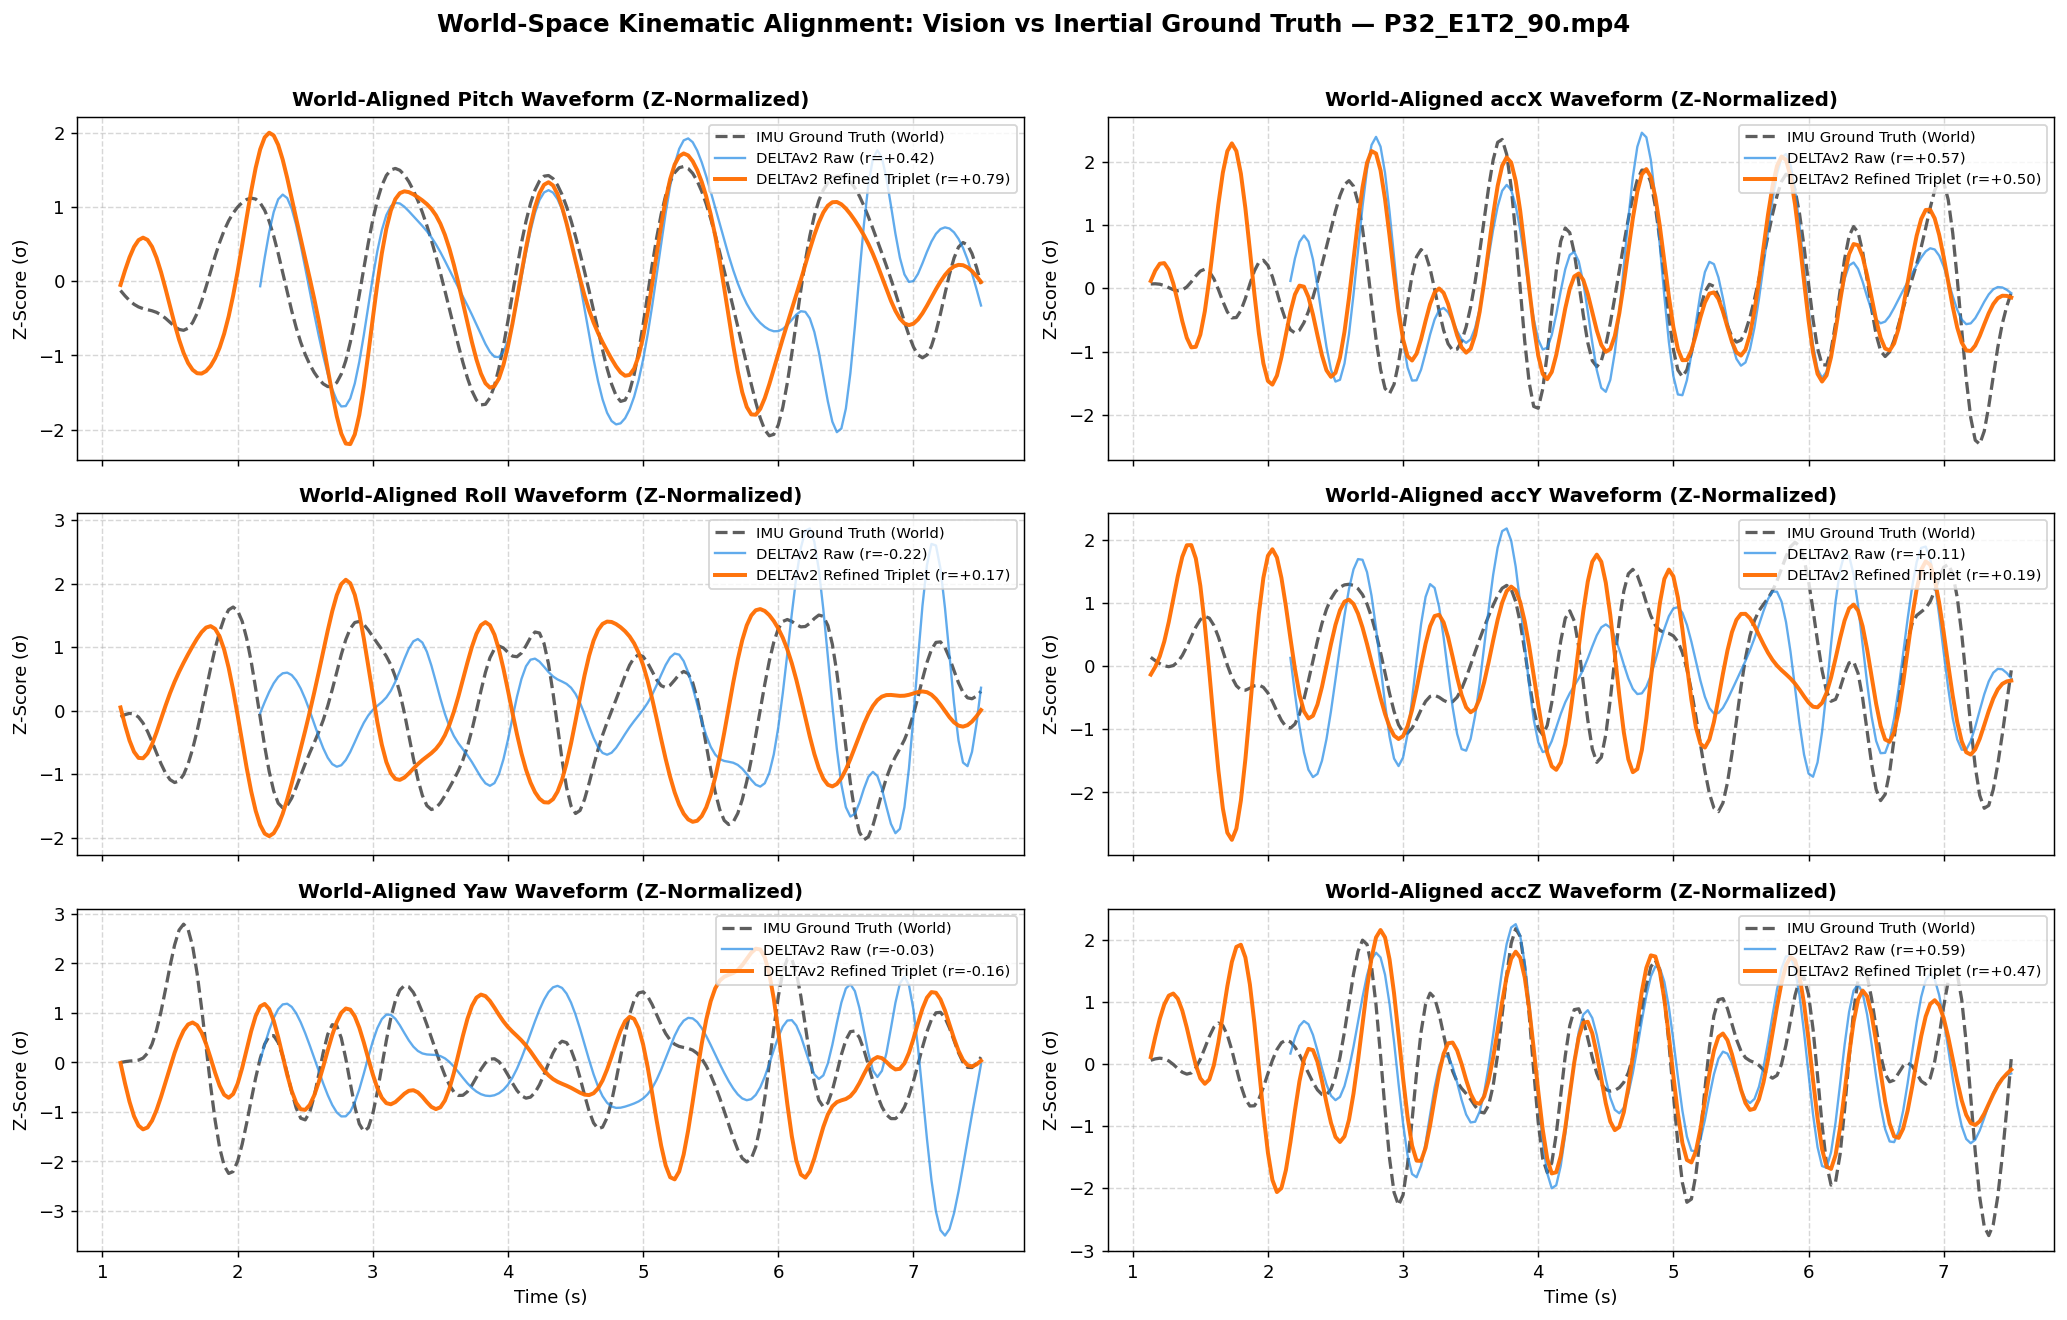

In [2]:
from src.analysis.signal_extractor import extract_aligned_signals, load_cutoffs
from src.metrics.waveform.cross_correlation import calculate_cross_correlation

lowcut, highcut = load_cutoffs(project_root)
video_name = "P32_E1T2_90.mp4"

ref_npz = project_root / "data" / "inference_results" / "refined" / f"delta_v2_refined_{video_name}.npz"
raw_npz = project_root / "data" / "inference_results" / "raw" / f"delta_v2_raw_{video_name}.npz"

sig_ref = extract_aligned_signals(ref_npz, lowcut=lowcut, highcut=highcut, source="triplet")
sig_raw = extract_aligned_signals(raw_npz, lowcut=lowcut, highcut=highcut, source="triplet")

t_vis = sig_ref["t_vis"]
fps = sig_ref["fps"]
corrs_ref = sig_ref["correlations"]
corrs_raw = sig_raw["correlations"]

print(f"Video Evaluated     : {video_name} | Bandpass: [{lowcut:.2f} - {highcut:.2f} Hz] | Sync Lag: {sig_ref['temporal_lag']:+d} frames ({sig_ref['temporal_lag']/fps:+.2f}s)")
print(f"Refined Triplet (r) : Pitch={corrs_ref['Pitch']:+.3f} | AccX={corrs_ref['accX']:+.3f} | AccY={corrs_ref['accY']:+.3f} | AccZ={corrs_ref['accZ']:+.3f}")
print(f"Raw Baseline    (r) : Pitch={corrs_raw['Pitch']:+.3f} | AccX={corrs_raw['accX']:+.3f} | AccY={corrs_raw['accY']:+.3f} | AccZ={corrs_raw['accZ']:+.3f}")

def z_norm(x):
    s = np.std(x)
    return (x - np.mean(x)) / s if s > 1e-8 else x - np.mean(x)

fig, axes = plt.subplots(3, 2, figsize=(16, 10), sharex=True)
channels = [("Pitch", "deg"), ("accX", "m/s²"), ("Roll", "deg"), ("accY", "m/s²"), ("Yaw", "deg"), ("accZ", "m/s²")]

for ax, (ch, unit) in zip(axes.flatten(), channels):
    gt_y = z_norm(sig_ref[f"gt_{ch}"])
    raw_y = z_norm(sig_raw[ch])
    ref_y = z_norm(sig_ref[ch])

    ax.plot(sig_ref["t_vis"], gt_y, color="#424242", ls="--", lw=1.8, alpha=0.85, label="IMU Ground Truth (World)")
    ax.plot(sig_raw["t_vis"], raw_y, color="#1E88E5", lw=1.3, alpha=0.70, label=f"DELTAv2 Raw (r={corrs_raw[ch]:+.2f})")
    ax.plot(sig_ref["t_vis"], ref_y, color="#FF6D00", lw=2.2, alpha=0.95, label=f"DELTAv2 Refined Triplet (r={corrs_ref[ch]:+.2f})")
    ax.set_title(f"World-Aligned {ch} Waveform (Z-Normalized)", fontsize=11, fontweight="bold")
    ax.set_ylabel("Z-Score (σ)")
    ax.legend(loc="upper right", fontsize=8.2)
    ax.grid(True, ls="--", alpha=0.5)

axes[2, 0].set_xlabel("Time (s)")
axes[2, 1].set_xlabel("Time (s)")
fig.suptitle(f"World-Space Kinematic Alignment: Vision vs Inertial Ground Truth — {video_name}", fontsize=13.5, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()

## 2. Biomechanical Swap Disentanglement: Rolling Cross-Correlation Analysis

A core scientific contribution of this repository is distinguishing between:
- **True Identity Swaps ($90^\circ$ Sagittal & $45^\circ$ Oblique Views)**: Where the swinging leg crosses and occludes the stance leg in the 2D image plane, causing trackers without geometric pruning to jump onto the opposite limb (which oscillates $180^\circ$ out of phase, producing sustained rolling correlation $r(t) < -0.35$).
- **Axial Monocular Depth Artifacts ($0^\circ$ Frontal & $180^\circ$ Posterior Views)**: Where left and right legs remain separated by pelvic width along image axis $X$ and **never intersect**, so limb swap is physically impossible; antiphase arises purely from monocular depth foreshortening along optical axis $Z$.

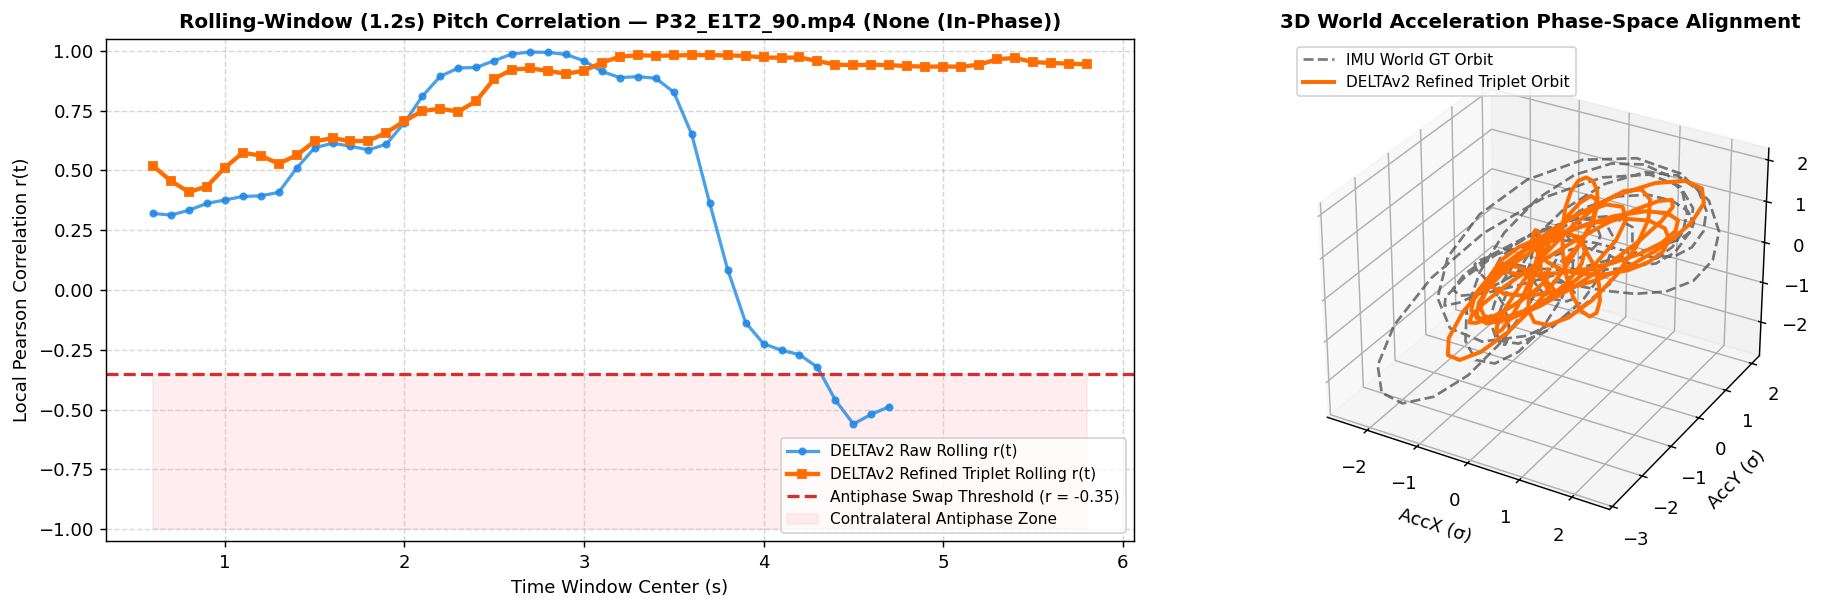

In [3]:
from src.metrics.waveform.cross_correlation import detect_identity_swap_cross_correlation

def compute_rolling_corr_curve(y_p, y_t, fps_val, win_sec=1.2, step_sec=0.1):
    w = max(4, int(round(fps_val * win_sec)))
    st = max(1, int(round(fps_val * step_sec)))
    t_centers, r_vals = [], []
    for s in range(0, len(y_p) - w + 1, st):
        sp, st_seg = y_p[s:s+w], y_t[s:s+w]
        if np.std(sp) > 1e-5 and np.std(st_seg) > 1e-5:
            r_vals.append(float(np.corrcoef(sp, st_seg)[0, 1]))
            t_centers.append((s + w / 2.0) / fps_val)
    return np.array(t_centers), np.array(r_vals)

# Compare an in-phase sagittal video (P32_E1T2_90.mp4) with a crossover-challenged trial
tc_ref, rc_ref = compute_rolling_corr_curve(sig_ref["Pitch"], sig_ref["gt_Pitch"], fps)
tc_raw, rc_raw = compute_rolling_corr_curve(sig_raw["Pitch"], sig_raw["gt_Pitch"], fps)
swap_res = detect_identity_swap_cross_correlation(sig_ref["Pitch"], sig_ref["gt_Pitch"], fps=fps, angle="90")

fig = plt.figure(figsize=(16, 4.8))
ax1 = fig.add_subplot(1, 2, 1)
ax1.plot(tc_raw, rc_raw, color="#1E88E5", lw=1.8, marker="o", ms=3.5, alpha=0.8, label="DELTAv2 Raw Rolling r(t)")
ax1.plot(tc_ref, rc_ref, color="#FF6D00", lw=2.4, marker="s", ms=4.0, label="DELTAv2 Refined Triplet Rolling r(t)")
ax1.axhline(-0.35, color="#D32F2F", ls="--", lw=1.8, label="Antiphase Swap Threshold (r = -0.35)")
ax1.fill_between(tc_ref, -1.0, -0.35, color="#FFCDD2", alpha=0.35, label="Contralateral Antiphase Zone")
ax1.set_ylim(-1.05, 1.05)
ax1.set_title(f"Rolling-Window (1.2s) Pitch Correlation — {video_name} ({swap_res.diagnostic})", fontsize=11, fontweight="bold")
ax1.set_xlabel("Time Window Center (s)")
ax1.set_ylabel("Local Pearson Correlation r(t)")
ax1.legend(loc="lower right", fontsize=8.5)
ax1.grid(True, ls="--", alpha=0.5)

# 3D Acceleration State-Space Comparison (World Frame)
ax2 = fig.add_subplot(1, 2, 2, projection="3d")
ax2.plot(z_norm(sig_ref["gt_accX"]), z_norm(sig_ref["gt_accY"]), z_norm(sig_ref["gt_accZ"]), color="#424242", ls="--", lw=1.5, alpha=0.7, label="IMU World GT Orbit")
ax2.plot(z_norm(sig_ref["accX"]), z_norm(sig_ref["accY"]), z_norm(sig_ref["accZ"]), color="#FF6D00", lw=2.2, label="DELTAv2 Refined Triplet Orbit")
ax2.set_title("3D World Acceleration Phase-Space Alignment", fontsize=11, fontweight="bold")
ax2.set_xlabel("AccX (σ)")
ax2.set_ylabel("AccY (σ)")
ax2.set_zlabel("AccZ (σ)")
ax2.legend(loc="upper left", fontsize=8.5)

plt.tight_layout()
plt.show()

## 3. Comprehensive 40-Video SOTA Benchmark Synthesis

Finally, we load `results/benchmark_40_metrics.json` containing the full evaluation across all **40 stratified Gait360 videos** and visualize the comparative performance of the 4 evaluated methods:
1. **Dummy Baseline (2D OpenPose Keypoint Lift)**
2. **DELTAv2 Raw Baseline (Unpruned Initial Triplet)**
3. **DELTAv2 Refined Point Cloud (SVD Plane Fit)**
4. **DELTAv2 Refined Triplet (Proposed 3-Stage Geometric Pruning)**

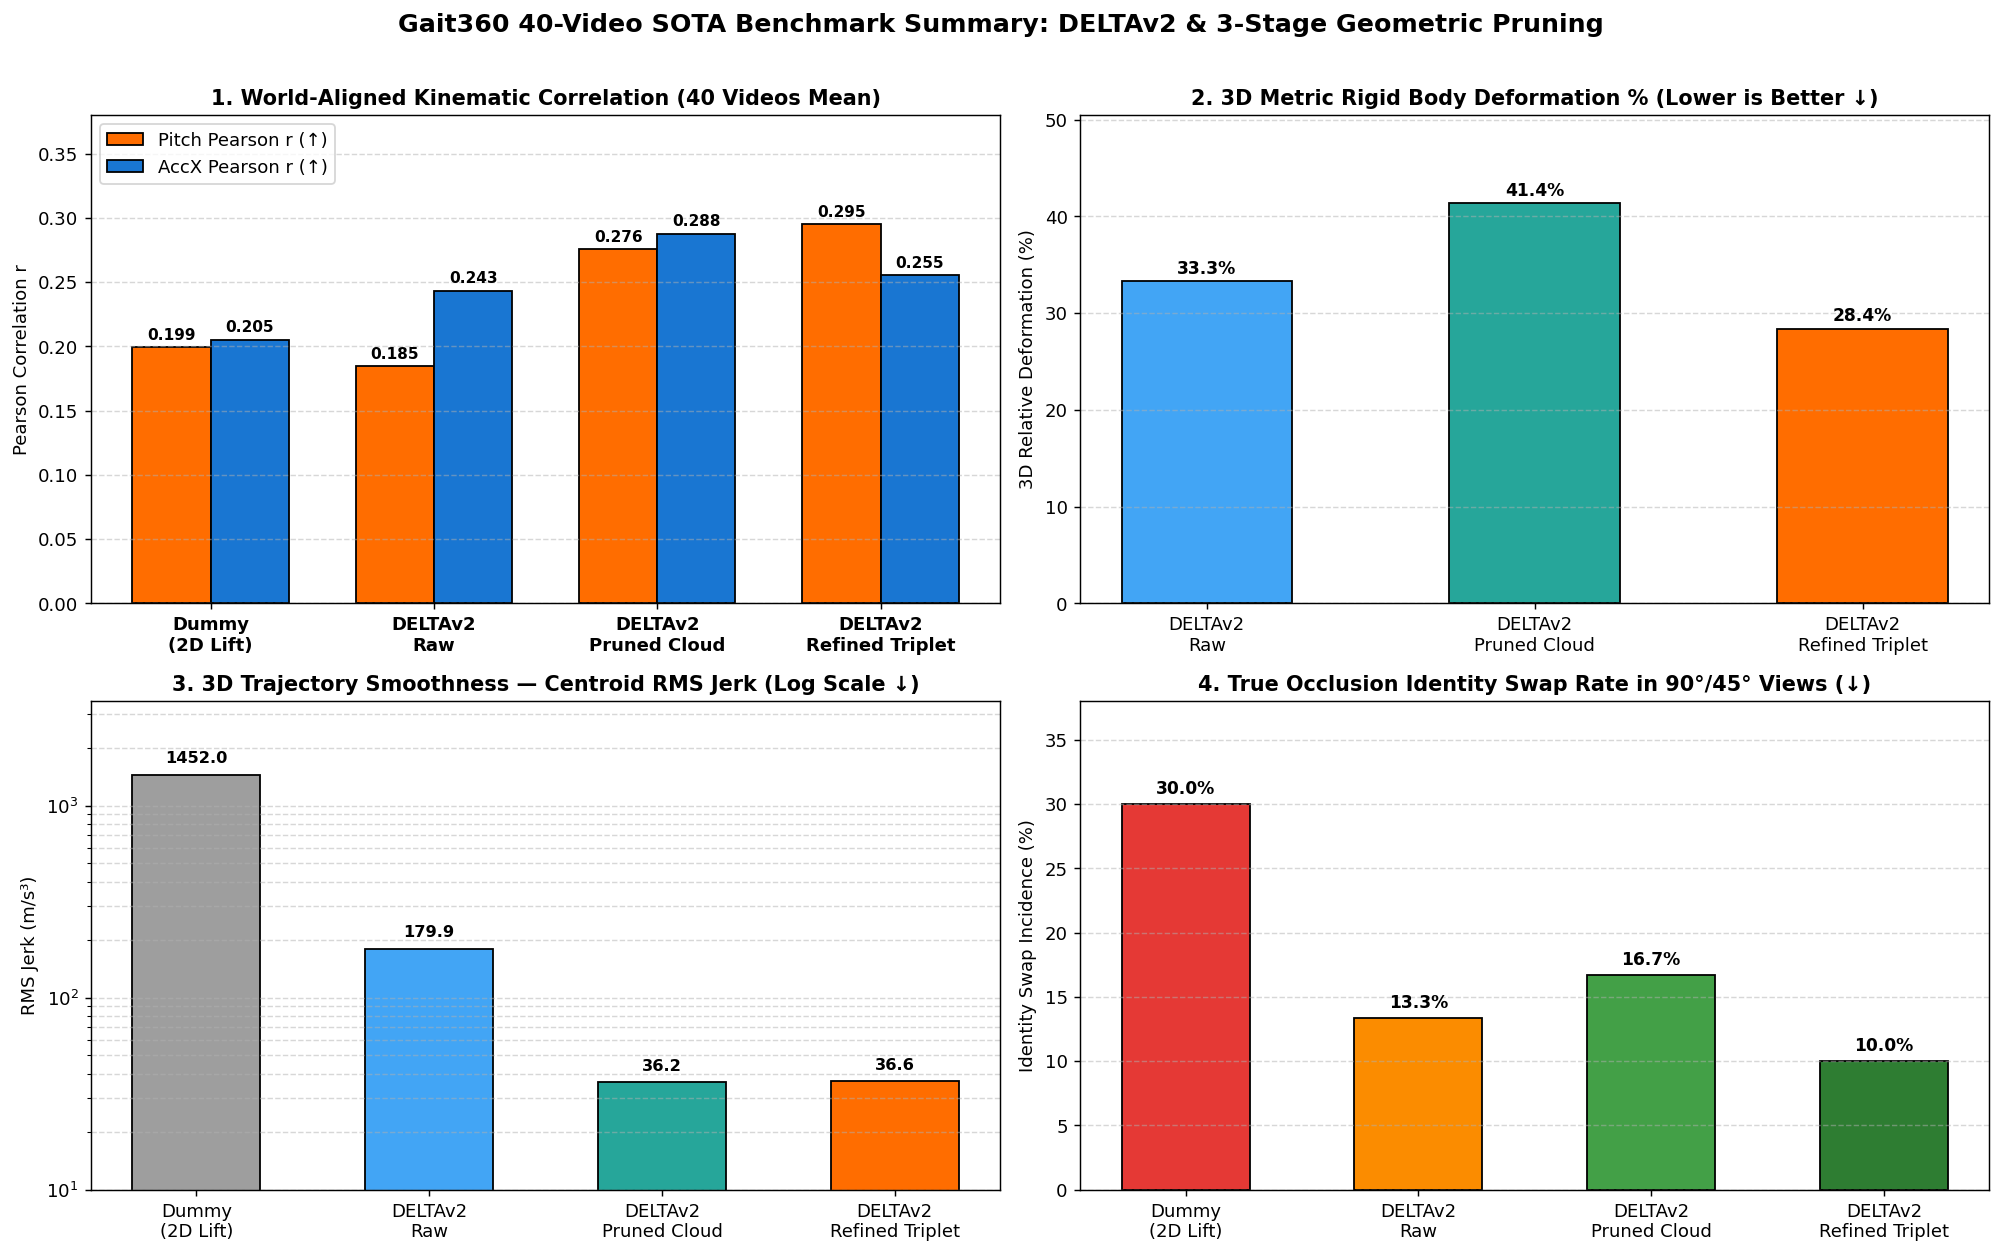

In [4]:
with open(project_root / "results" / "benchmark_40_metrics.json", "r", encoding="utf-8") as f:
    bench_data = json.load(f)

evals = bench_data["evaluations_by_video"]
methods = ["dummy", "raw", "refined_cloud", "refined_triplet"]
method_labels = ["Dummy\n(2D Lift)", "DELTAv2\nRaw", "DELTAv2\nPruned Cloud", "DELTAv2\nRefined Triplet"]
palette = ["#9E9E9E", "#42A5F5", "#26A69A", "#FF6D00"]

def get_metric_means(m_key):
    return [float(np.mean([v["methods"][m][m_key] for v in evals.values()])) for m in methods]

pitch_r_means = get_metric_means("pearson_pitch")
accx_r_means = get_metric_means("pearson_accX")
def_means = get_metric_means("relative_deformation_percent")
jerk_means = get_metric_means("rms_jerk")

crossover_vids = [v for v in evals.values() if str(v["angle"]).strip().lower() in ("90", "45")]
swap_rates = [
    sum(1 for v in crossover_vids if v["methods"][m].get("has_identity_swap", False)) / len(crossover_vids) * 100.0
    for m in methods
]

fig, axes = plt.subplots(2, 2, figsize=(15.5, 9.5))

# Panel 1: Kinematic Waveform Correlation (Pitch & AccX Pearson r)
x = np.arange(len(methods))
w = 0.35
b1 = axes[0, 0].bar(x - w/2, pitch_r_means, w, label="Pitch Pearson r (↑)", color="#FF6D00", edgecolor="black")
b2 = axes[0, 0].bar(x + w/2, accx_r_means, w, label="AccX Pearson r (↑)", color="#1976D2", edgecolor="black")
axes[0, 0].set_xticks(x)
axes[0, 0].set_xticklabels(method_labels, fontweight="bold")
axes[0, 0].set_ylim(0, 0.38)
axes[0, 0].set_title("1. World-Aligned Kinematic Correlation (40 Videos Mean)", fontsize=11.5, fontweight="bold")
axes[0, 0].set_ylabel("Pearson Correlation r")
axes[0, 0].legend(loc="upper left")
axes[0, 0].grid(axis="y", ls="--", alpha=0.5)
for b in list(b1) + list(b2):
    axes[0, 0].text(b.get_x() + b.get_width()/2, b.get_height() + 0.006, f"{b.get_height():.3f}", ha="center", fontsize=8.5, fontweight="bold")

# Panel 2: 3D Rigid Body Deformation (%)
b_def = axes[0, 1].bar(method_labels[1:], def_means[1:], color=palette[1:], edgecolor="black", width=0.52)
axes[0, 1].set_ylim(0, max(def_means[1:]) * 1.22)
axes[0, 1].set_title("2. 3D Metric Rigid Body Deformation % (Lower is Better ↓)", fontsize=11.5, fontweight="bold")
axes[0, 1].set_ylabel("3D Relative Deformation (%)")
axes[0, 1].grid(axis="y", ls="--", alpha=0.5)
for b in b_def:
    axes[0, 1].text(b.get_x() + b.get_width()/2, b.get_height() + 0.8, f"{b.get_height():.1f}%", ha="center", fontsize=9.5, fontweight="bold")

# Panel 3: 3D Trajectory Smoothness — RMS Jerk (m/s³, log scale)
b_jerk = axes[1, 0].bar(method_labels, jerk_means, color=palette, edgecolor="black", width=0.55)
axes[1, 0].set_yscale("log")
axes[1, 0].set_ylim(10, 3500)
axes[1, 0].set_title("3. 3D Trajectory Smoothness — Centroid RMS Jerk (Log Scale ↓)", fontsize=11.5, fontweight="bold")
axes[1, 0].set_ylabel("RMS Jerk (m/s³)")
axes[1, 0].grid(axis="y", which="both", ls="--", alpha=0.5)
for b in b_jerk:
    axes[1, 0].text(b.get_x() + b.get_width()/2, b.get_height() * 1.15, f"{b.get_height():.1f}", ha="center", fontsize=9, fontweight="bold")

# Panel 4: True Occlusion Identity Swap Rate (90° & 45° Crossover Views)
b_swap = axes[1, 1].bar(method_labels, swap_rates, color=["#E53935", "#FB8C00", "#43A047", "#2E7D32"], edgecolor="black", width=0.55)
axes[1, 1].set_ylim(0, 38)
axes[1, 1].set_title("4. True Occlusion Identity Swap Rate in 90°/45° Views (↓)", fontsize=11.5, fontweight="bold")
axes[1, 1].set_ylabel("Identity Swap Incidence (%)")
axes[1, 1].grid(axis="y", ls="--", alpha=0.5)
for b in b_swap:
    axes[1, 1].text(b.get_x() + b.get_width()/2, b.get_height() + 0.8, f"{b.get_height():.1f}%", ha="center", fontsize=9.5, fontweight="bold")

fig.suptitle("Gait360 40-Video SOTA Benchmark Summary: DELTAv2 & 3-Stage Geometric Pruning", fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()